<a href="https://colab.research.google.com/github/truong6478-svg/Videal-Internship-Phase3-Image-Classification/blob/main/notebooks/3_1_CNN_CIFAR10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Đang sử dụng thiết bị: cuda
Đang tải dữ liệu CIFAR-10...


100%|██████████| 170M/170M [27:20<00:00, 104kB/s]


Đã tải xong CIFAR-10! Bắt đầu huấn luyện...
Epoch [1/10] - Train Loss: 1.5269, Train Acc: 43.61% | Test Loss: 1.1703, Test Acc: 56.95%
Epoch [2/10] - Train Loss: 1.2131, Train Acc: 56.34% | Test Loss: 0.9834, Test Acc: 65.12%
Epoch [3/10] - Train Loss: 1.0893, Train Acc: 61.09% | Test Loss: 0.9497, Test Acc: 65.98%
Epoch [4/10] - Train Loss: 1.0134, Train Acc: 64.03% | Test Loss: 0.8646, Test Acc: 69.68%
Epoch [5/10] - Train Loss: 0.9616, Train Acc: 66.10% | Test Loss: 0.8002, Test Acc: 72.08%
Epoch [6/10] - Train Loss: 0.9223, Train Acc: 67.43% | Test Loss: 0.7697, Test Acc: 72.86%
Epoch [7/10] - Train Loss: 0.8893, Train Acc: 68.54% | Test Loss: 0.7441, Test Acc: 74.02%
Epoch [8/10] - Train Loss: 0.8570, Train Acc: 69.84% | Test Loss: 0.7036, Test Acc: 75.23%
Epoch [9/10] - Train Loss: 0.8289, Train Acc: 70.93% | Test Loss: 0.7011, Test Acc: 75.85%
Epoch [10/10] - Train Loss: 0.8187, Train Acc: 71.35% | Test Loss: 0.6597, Test Acc: 76.80%


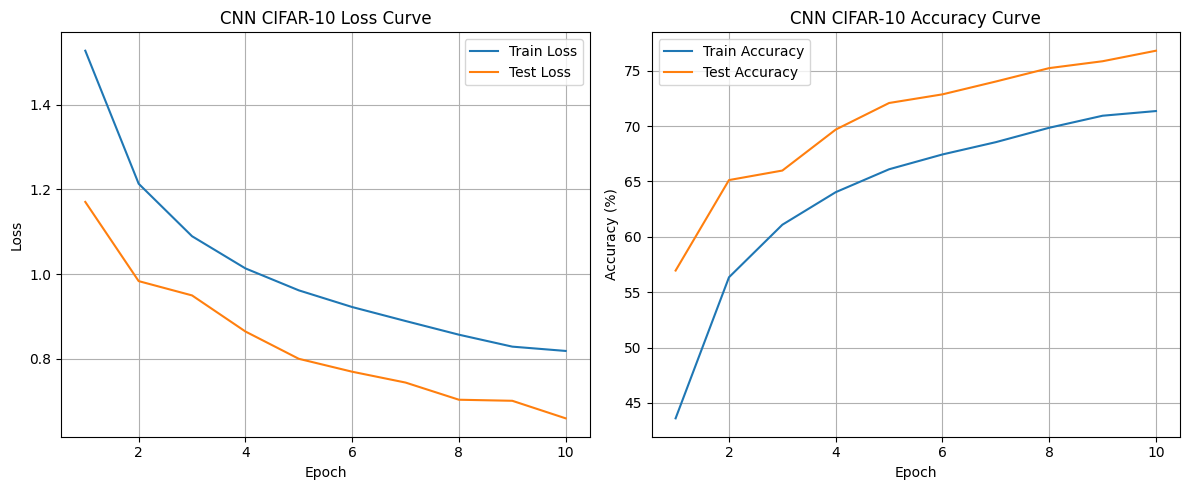

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Thiết lập thiết bị & thư mục lưu kết quả
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Đang sử dụng thiết bị:", device)
os.makedirs("results", exist_ok=True)

# 2. Tải và chuẩn hóa dữ liệu CIFAR-10
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

print("Đang tải dữ liệu CIFAR-10...")
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=0)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False, num_workers=0)
print("Đã tải xong CIFAR-10! Bắt đầu huấn luyện...")

# 3. Xây dựng mạng CNN cơ bản
class BasicCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(BasicCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 16x16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 8x8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = BasicCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. Huấn luyện và đánh giá
epochs = 10
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100. * correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # Đánh giá trên tập test
    model.eval()
    t_loss, t_correct, t_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            t_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            t_total += labels.size(0)
            t_correct += predicted.eq(labels).sum().item()

    test_loss = t_loss / t_total
    test_acc = 100. * t_correct / t_total
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    print(f"Epoch [{epoch+1}/{epochs}] - Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}%")

# 5. Vẽ và lưu biểu đồ kết quả
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_losses, label='Train Loss')
plt.plot(range(1, epochs+1), test_losses, label='Test Loss')
plt.title('CNN CIFAR-10 Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), train_accs, label='Train Accuracy')
plt.plot(range(1, epochs+1), test_accs, label='Test Accuracy')
plt.title('CNN CIFAR-10 Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("results/cifar10_learning_curve.png", dpi=150)
plt.show()